# Local Conditional Mutual Information (LCMI)
**A Scalable Information-Theoretic Framework for Interpretable and Nonlinear Spatially Varying Effect Modelling**



## King County Dataset

Source: https://geodacenter.github.io/data-and-lab/KingCounty-HouseSales2015/

Results generated for the Paper 

------Main Text --------------------------------------------

1) Figure 4. King County application: WLS-reconstructed coefficient surfaces from the LCMI model.  **source**: results/lcmi_case2_KingCounty_LCMI_WLS.png

2) Figure 5. King County application: contribution-based PDP decomposition from the LCMI model. **source**:results/lcmi_case2_KingCounty_LCMI_PDP.png

3) Table 2. LCMI feature contribution summary and GeoShapley feature importance for the King County application. **source**: results/lcmi_case2_KingCounty_Importance_Table.csv

------Supplementary Materials --------------------------------------------

3) Figure S1. Spatial distribution of the six focal variables in the King County house price dataset. **source**: results/lcmi_case2_KingCounty_Original.png

4) Figure S2. King County application: raw local dependence surfaces from the LCMI model. **source**: results/lcmi_case2_KingCounty_LCMI_lws.png


5) Figure S3. King County application: GWR-smoothed GeoShapley spatial surfaces. **source**:results/lcmi_case2_KingCounty_geoshapley_pdp.png

6) Figure S4. King County application: GeoShapley PDPs.  **source**: results/lcmi_case2_KingCounty_geoshapley_pdp.png



## 1 Read Data

In [34]:
import pandas as pd
import numpy as np
data_path='data/kc_house_data.csv'
df_raw = pd.read_csv(data_path)
df = df_raw.copy()
df = df.dropna(subset=['price', 'lat', 'long'])
df = df[(df['price'] > 0) & (df['bedrooms'] < 20) & (df['sqft_living'] > 0)].copy()
df = df[df['long'] < -121.676].copy()
df['log_price']       = np.log(df['price'])
df['log_sqft_living'] = np.log(df['sqft_living'])
df['log_sqft_lot'] = np.log(df['sqft_lot'])
df['age']       = 2015 - df['yr_built']
df['waterfront']      = df['waterfront'].astype(int)
df = df.reset_index(drop=True)
 
PREFIX="results/lcmi_case2"
SEED=42

DPI=300
# SAMPLE_N = 3000
# if SAMPLE_N is not None and SAMPLE_N < len(df):
#     df = df.sample(n=SAMPLE_N, random_state=SEED).reset_index(drop=True)

u='long'
v='lat'
y='log_price'      
xlist=['log_sqft_living','log_sqft_lot', 'grade','waterfront','view','age']

# 2 Run Models

## 2-1 LCMI model

In [35]:
from lcmi import CMI
model = CMI(df, u=u, v=v, y=y, xlist=xlist,
             bw_candidates=[200, 250, 300, 350, 400, 450])
model.fit()
  

  [CMI.__init__] Building nn_idx at max_bw=470 ... 1.14s  shape=(21593, 471)
  [CMI.__init__] Building PDP sample points ... 11195 points selected

CMI.fit()  n=21593  p=6  vars=['log_sqft_living', 'log_sqft_lot', 'grade', 'waterfront', 'view', 'age']
  k search [log_sqft_living] ... best k=12
  BW search [log_sqft_living] k=12 ... best bw=464
  k search [log_sqft_lot] ... best k=12
  BW search [log_sqft_lot] k=12 ... best bw=386
  k search [grade] ... best k=10
  BW search [grade] k=10 ... best bw=450
  k search [waterfront] ... best k=6
  BW search [waterfront] k=6 ... best bw=442
  k search [view] ... best k=4
  BW search [view] k=4 ... best bw=464
  k search [age] ... best k=4
  BW search [age] k=4 ... best bw=400

  Selected k:  {'log_sqft_living': 12, 'log_sqft_lot': 12, 'grade': 10, 'waterfront': 6, 'view': 4, 'age': 4}
  Selected BW: {'log_sqft_living': 464, 'log_sqft_lot': 386, 'grade': 450, 'waterfront': 442, 'view': 464, 'age': 400}

  Computing CMI surfaces (n_jobs=6) ...
 

## 2-2 Geoshapley model

In [36]:
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score
from geoshapley import GeoShapleyExplainer

Y = df['log_price'].to_numpy(float)  # log_price
coords = np.column_stack([df["long"].to_numpy(float), df["lat"].to_numpy(float)])

X_geo = df[xlist + ["long", "lat"]].to_numpy(float)

gs_model = GradientBoostingRegressor(
    n_estimators=200, max_depth=5, random_state=42
)
gs_model.fit(X_geo, Y)
y_hat_gs = gs_model.predict(X_geo)
r2_geoshapley_backbone = r2_score(Y, y_hat_gs)  

rng = np.random.default_rng(42)
bg_idx = rng.choice(len(Y), size=min(150, len(Y)), replace=False)
background = X_geo[bg_idx]
predict_fn = lambda arr: gs_model.predict(np.asarray(arr, dtype=float))

try:
    explainer = GeoShapleyExplainer(predict_fn, background, g=2, exact=True)
except TypeError:
    explainer = GeoShapleyExplainer(predict_fn, background, g=2)

gs_r = explainer.explain(
    pd.DataFrame(X_geo, columns=xlist + ["long", "lat"]),
    n_jobs=20,
)


  0%|          | 0/21593 [00:00<?, ?it/s]

In [45]:
print("GeoShapley backbone R² =", r2_geoshapley_backbone)
print(f"GeoShapley backbone R² = {r2_geoshapley_backbone:.4f}")

GeoShapley backbone R² = 0.9219541389040422
GeoShapley backbone R² = 0.9220


# 3 Result Comparison

## 3-0 Original Value

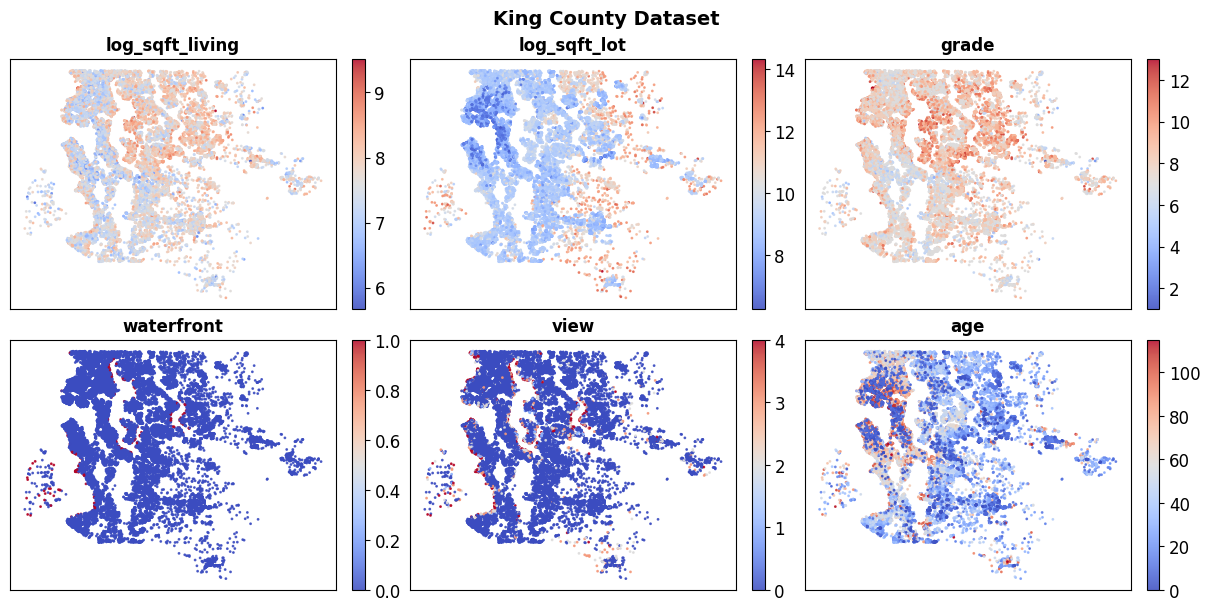

In [50]:
import matplotlib.pyplot as plt
TITLE_FS = 12
TICK_FS = 10
CBAR_TICK_FS = 12

fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
axs = axs.ravel()

for j, vn in enumerate(xlist):
    ax = axs[j]
    z = df[vn].to_numpy()
    sc = ax.scatter(df["long"], df["lat"], c=z, s=1, cmap="coolwarm", alpha=0.85)

    ax.set_title(vn, fontsize=TITLE_FS, fontweight="bold")
    ax.tick_params(axis="both", which="major", labelsize=TICK_FS)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046)
    cbar.ax.tick_params(labelsize=CBAR_TICK_FS)

fig.suptitle("King County Dataset", fontsize=14, fontweight="bold")
plt.savefig(f"{PREFIX}_KingCounty_Original.png", dpi=DPI, bbox_inches="tight")

## 3-1 LCMI WLS surface

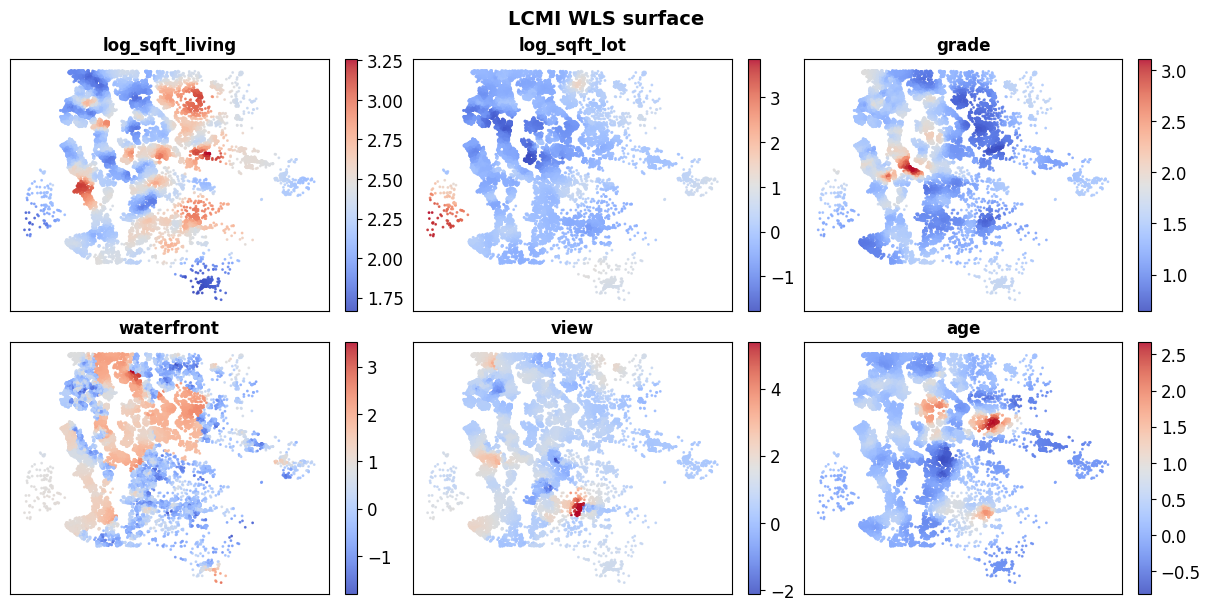

In [46]:
import matplotlib.pyplot as plt

TITLE_FS = 12
TICK_FS = 10
CBAR_TICK_FS = 12

res = model.result
fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
axs = axs.ravel()

for j, vn in enumerate(xlist):
    ax = axs[j]
    z = res.df_out[f"{vn}_wls"].to_numpy()
    sc = ax.scatter(df["long"], df["lat"], c=z, s=1, cmap="coolwarm", alpha=0.85)

    ax.set_title(vn, fontsize=TITLE_FS, fontweight="bold")
    ax.tick_params(axis="both", which="major", labelsize=TICK_FS)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046)
    cbar.ax.tick_params(labelsize=CBAR_TICK_FS)

fig.suptitle("LCMI WLS surface", fontsize=14, fontweight="bold")
plt.savefig(f"{PREFIX}_KingCounty_LCMI_WLS.png", dpi=DPI, bbox_inches="tight")

## 3-2 LCMI Raw  surface

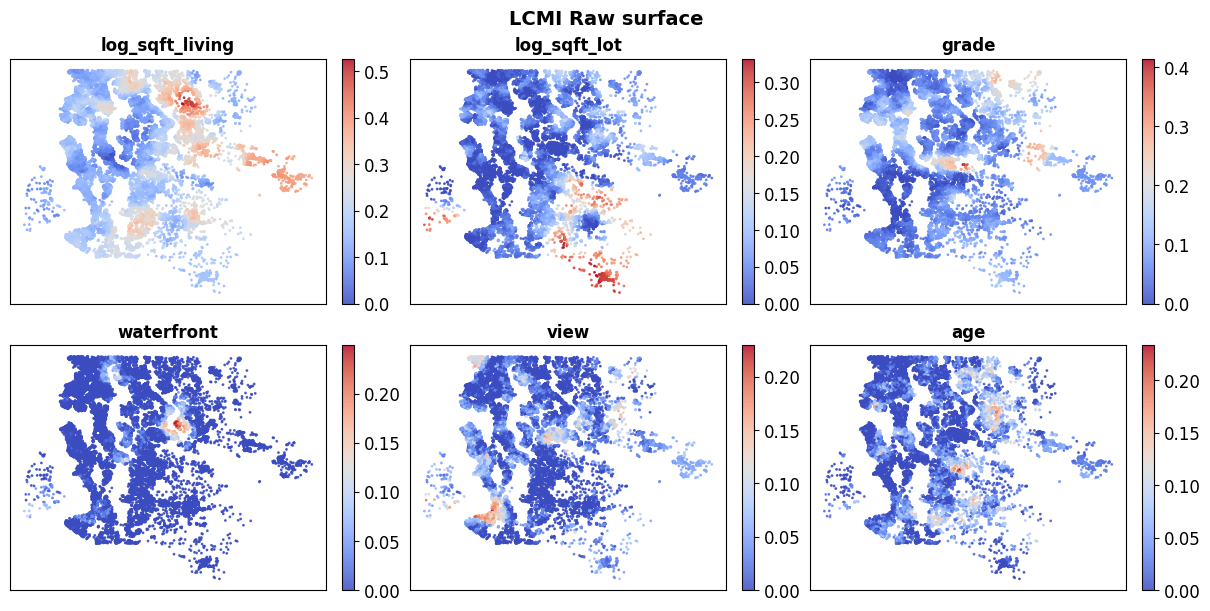

In [49]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
axs = axs.ravel()

for j, vn in enumerate(xlist):
    ax = axs[j]
    z = res.df_out[f"{vn}_lws"].to_numpy()
    sc = ax.scatter(df["long"], df["lat"], c=z, s=1, cmap="coolwarm", alpha=0.85)

    ax.set_title(vn, fontsize=TITLE_FS, fontweight="bold")
    ax.tick_params(axis="both", which="major", labelsize=TICK_FS)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046)
    cbar.ax.tick_params(labelsize=CBAR_TICK_FS)

fig.suptitle("LCMI Raw surface", fontsize=14, fontweight="bold")
plt.savefig(f"{PREFIX}_KingCounty_LCMI_lws.png", dpi=DPI, bbox_inches="tight")

## 3-3 Geoshapley Surface

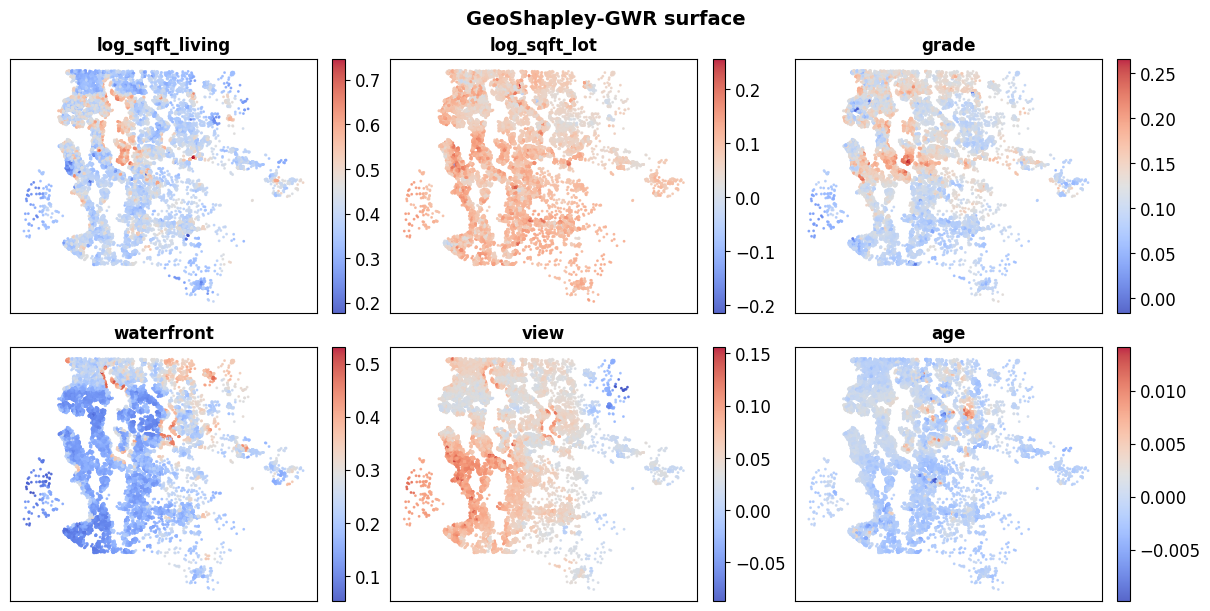

In [51]:
feat_idx = list(range(len(xlist)))
svc_gwr = gs_r.get_svc(
    feat_idx, coef_type="gwr", include_primary=True, coords=coords
)

fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
axs = axs.ravel()

for j, vn in enumerate(xlist):
    ax = axs[j]
    z = np.asarray(svc_gwr[:, j], float)
    sc = ax.scatter(df["long"], df["lat"], c=z, s=1, cmap="coolwarm", alpha=0.85)

    ax.set_title(vn, fontsize=TITLE_FS, fontweight="bold")
    ax.tick_params(axis="both", which="major", labelsize=TICK_FS)
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046)
    cbar.ax.tick_params(labelsize=CBAR_TICK_FS)

fig.suptitle("GeoShapley-GWR surface", fontsize=14, fontweight="bold")
plt.savefig(f"{PREFIX}_KingCounty_Geoshapley_GWR.png", dpi=DPI, bbox_inches="tight")

# 4 PDP Plot

## 4-1 Original LCMI PDP Plot

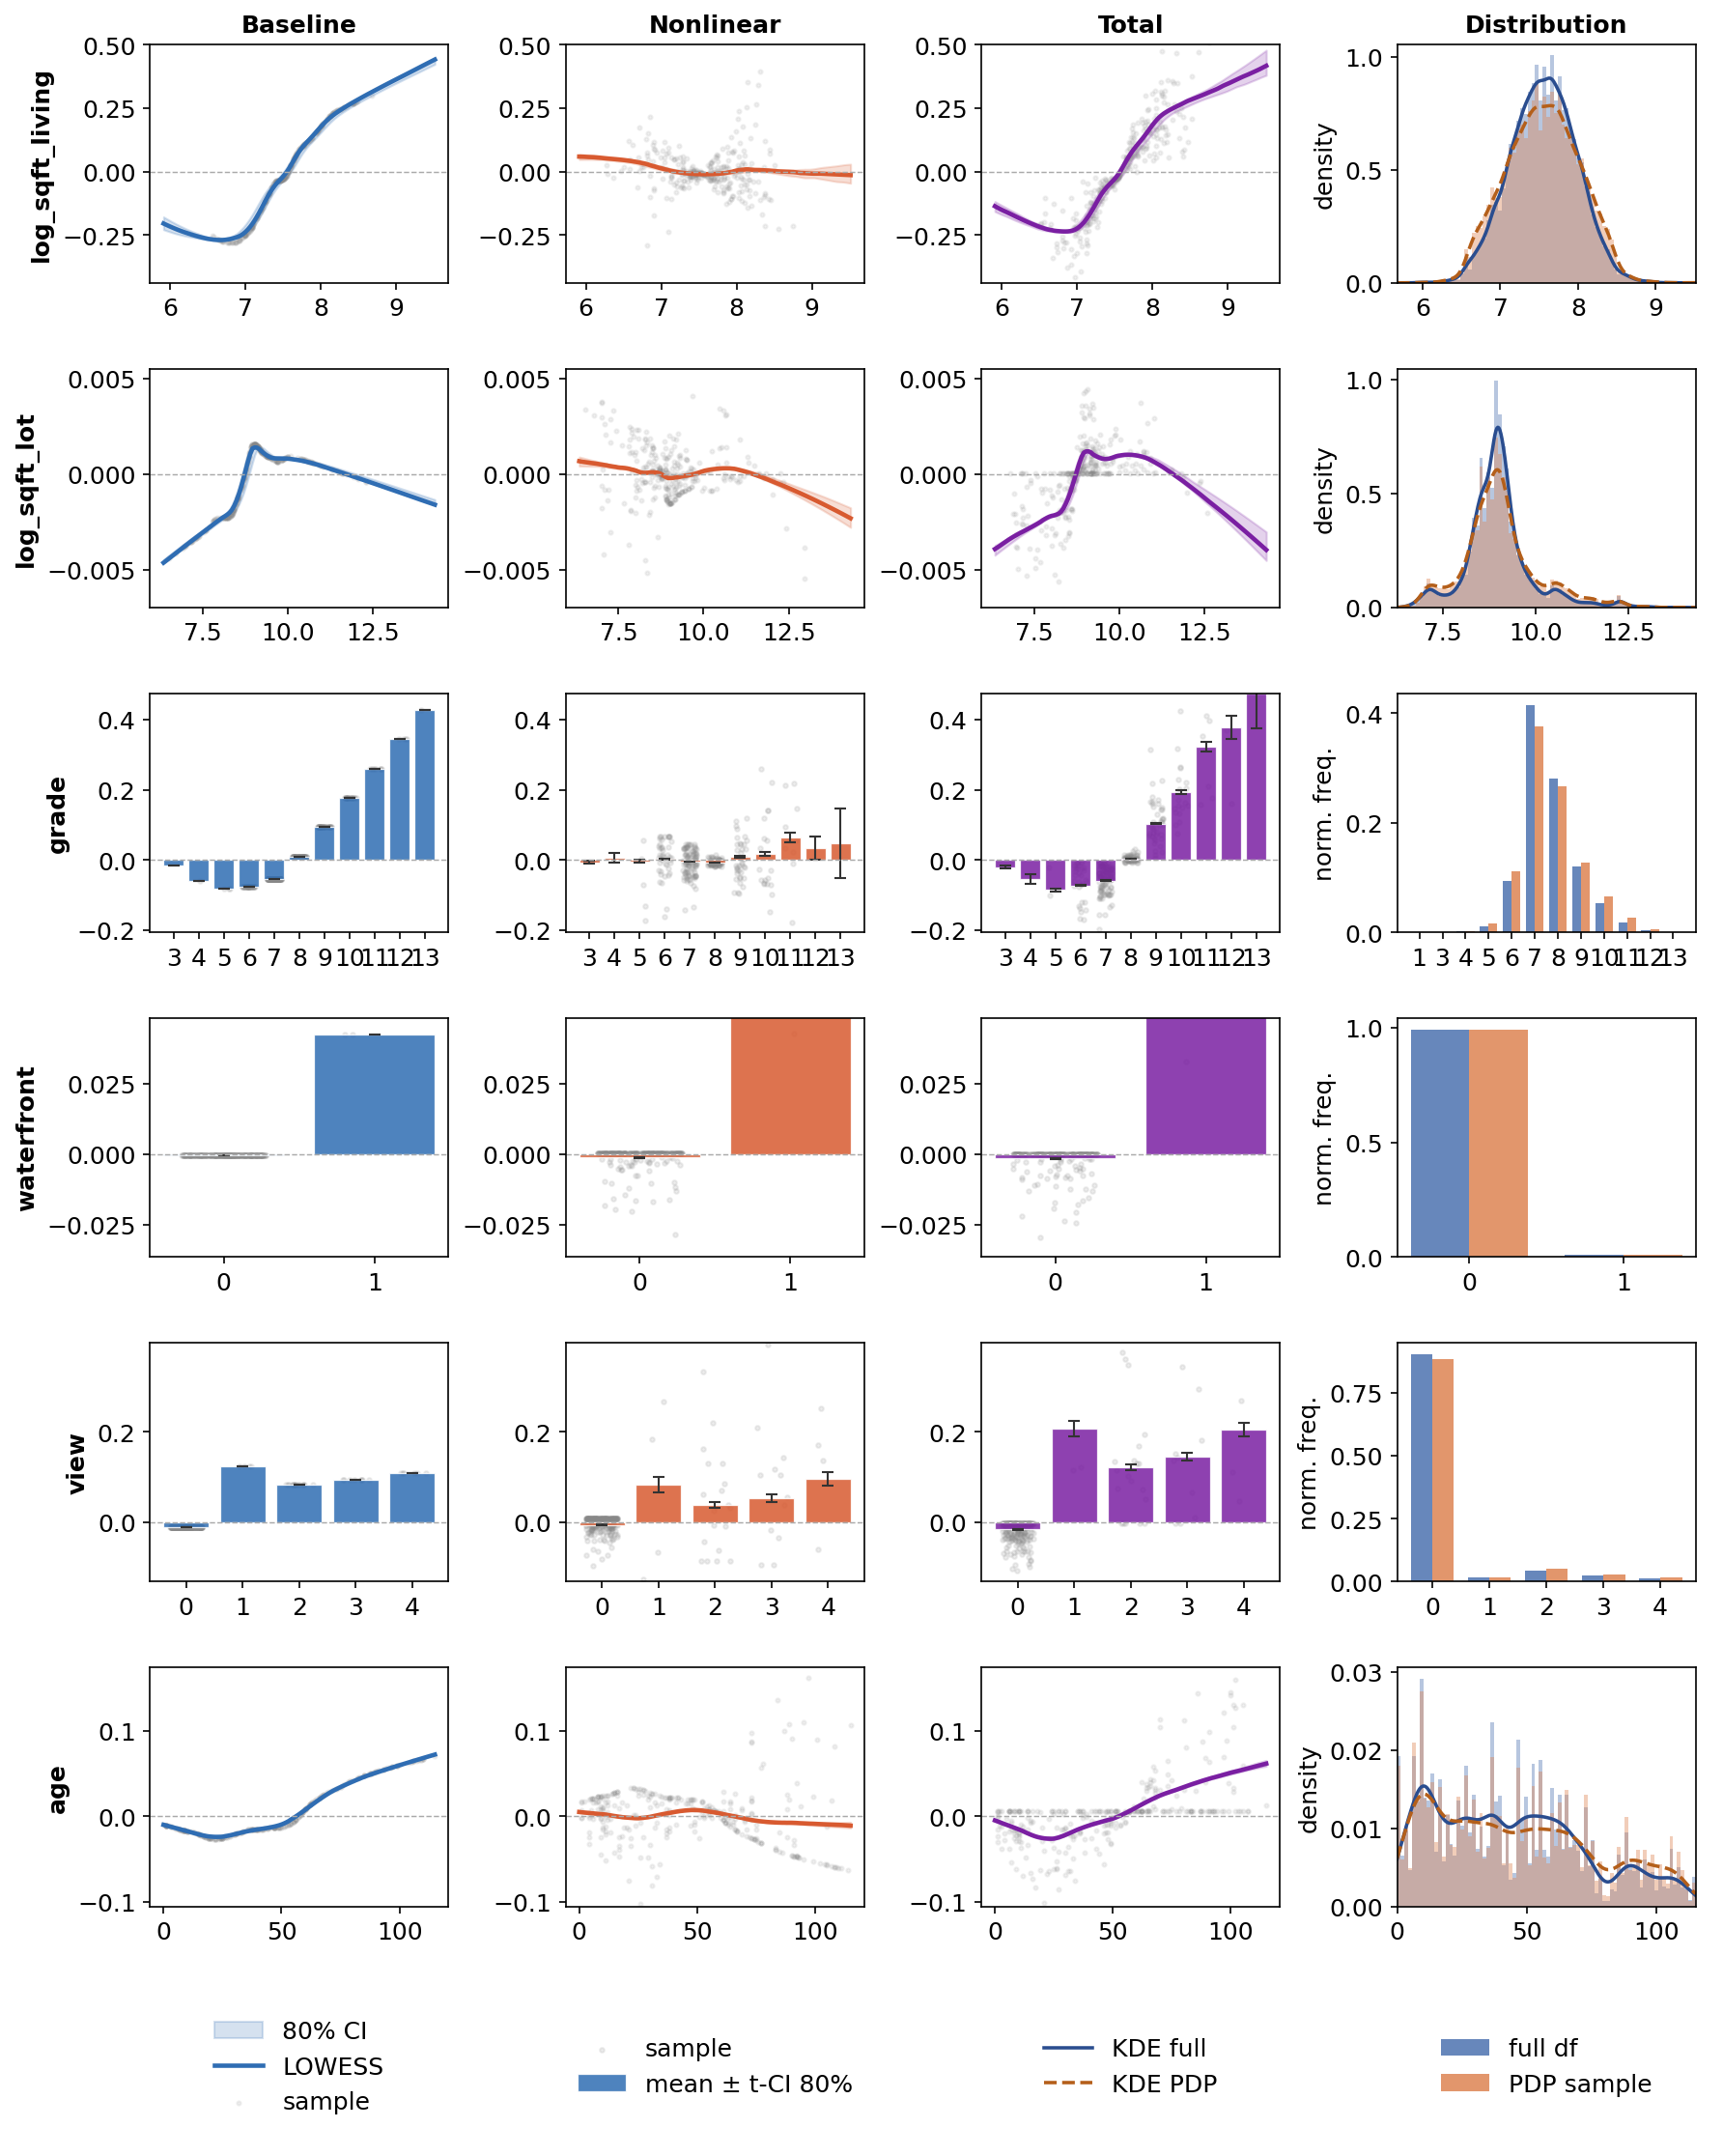

In [41]:
model.plot_pdp(
    separated_legend=True,
    show_suptitle=False,
    panel_side_inches=3.5,
    panel_aspect_hw=0.8,
    save=f"{PREFIX}_KingCounty_LCMI_PDP.png",
)

## 4-2 Original Geoshapley PDP Plot

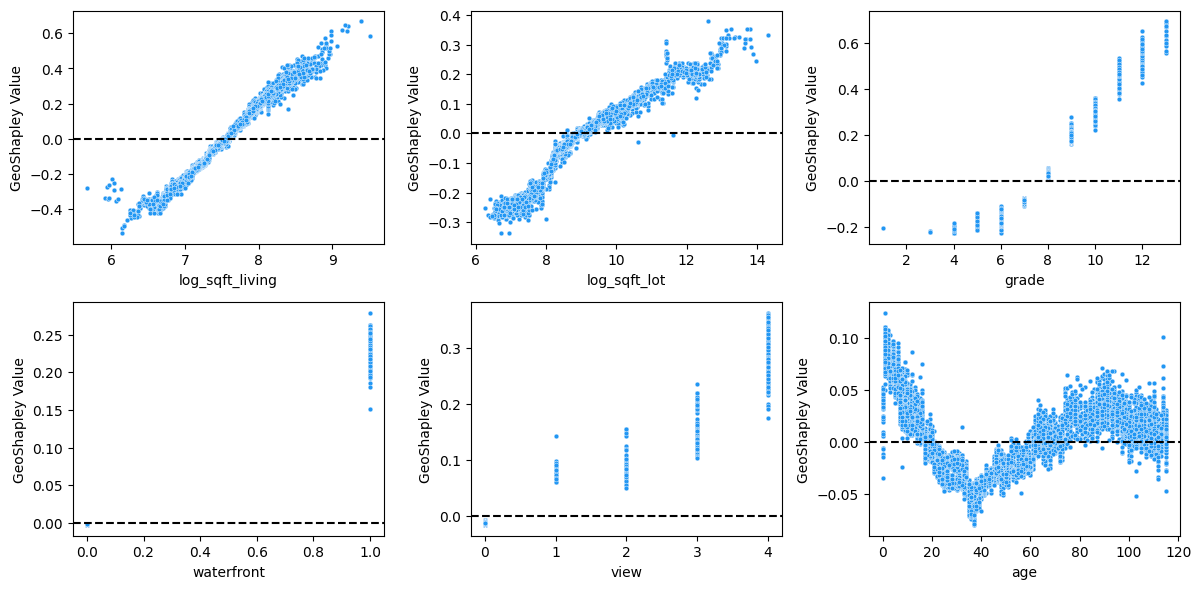

In [ ]:
gs_r.partial_dependence_plots(figsize=(12, 6), dpi=300)  
fig = plt.gcf()
fig.savefig(f"{PREFIX}_KingCounty_geoshapley_pdp.png", dpi=300, bbox_inches="tight")


## 4-3 Importance table 

In [43]:
# LCMI summary + GeoShapley importance join
summary = model.contribution_summary(print_table=False).copy()
if "variable" in summary.columns:
    summary = summary.set_index("variable")

P = np.asarray(gs_r.primary[:, : len(xlist)], dtype=float)
imp = np.mean(np.abs(P), axis=0)
geo_imp = pd.Series(imp, index=xlist, name="GeoShapley_mean_abs_primary")

importance_table = summary.join(geo_imp, how="left")
importance_table = importance_table.sort_values("mean_abs_total", ascending=False)
importance_table = importance_table.round(3)

# print(importance_table)
importance_table.to_csv(f"{PREFIX}_KingCounty_Importance_Table.csv")
importance_table

,mean_abs_baseline,mean_abs_residual,mean_abs_total,residual_share,GeoShapley_mean_abs_primary
variable,,,,,
log_sqft_living,0.133,0.047,0.132,0.356,0.140
grade,0.061,0.032,0.063,0.509,0.113
view,0.019,0.023,0.030,0.770,0.023
age,0.023,0.022,0.023,0.981,0.028
waterfront,0.001,0.003,0.003,0.983,0.003
log_sqft_lot,0.001,0.001,0.001,0.771,0.053
